<a href="https://colab.research.google.com/github/AniShriyak/Bio-Inspired-Lab/blob/main/BIS_Parallel_Cellular.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting Forest Fire Simulation...

Iteration: 10 | Burned cells: 8 | Adaptive time step: 60.0 minutes
Iteration: 20 | Burned cells: 8 | Adaptive time step: 60.0 minutes
Iteration: 30 | Burned cells: 8 | Adaptive time step: 60.0 minutes
Iteration: 40 | Burned cells: 8 | Adaptive time step: 60.0 minutes
Iteration: 50 | Burned cells: 8 | Adaptive time step: 60.0 minutes
Iteration: 60 | Burned cells: 8 | Adaptive time step: 60.0 minutes

Simulation Completed!


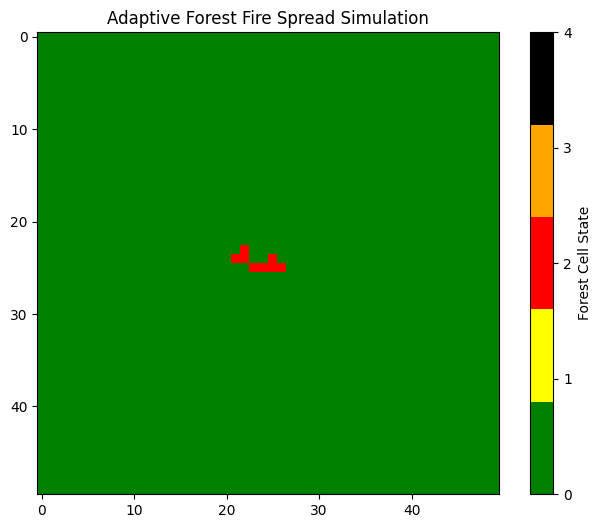

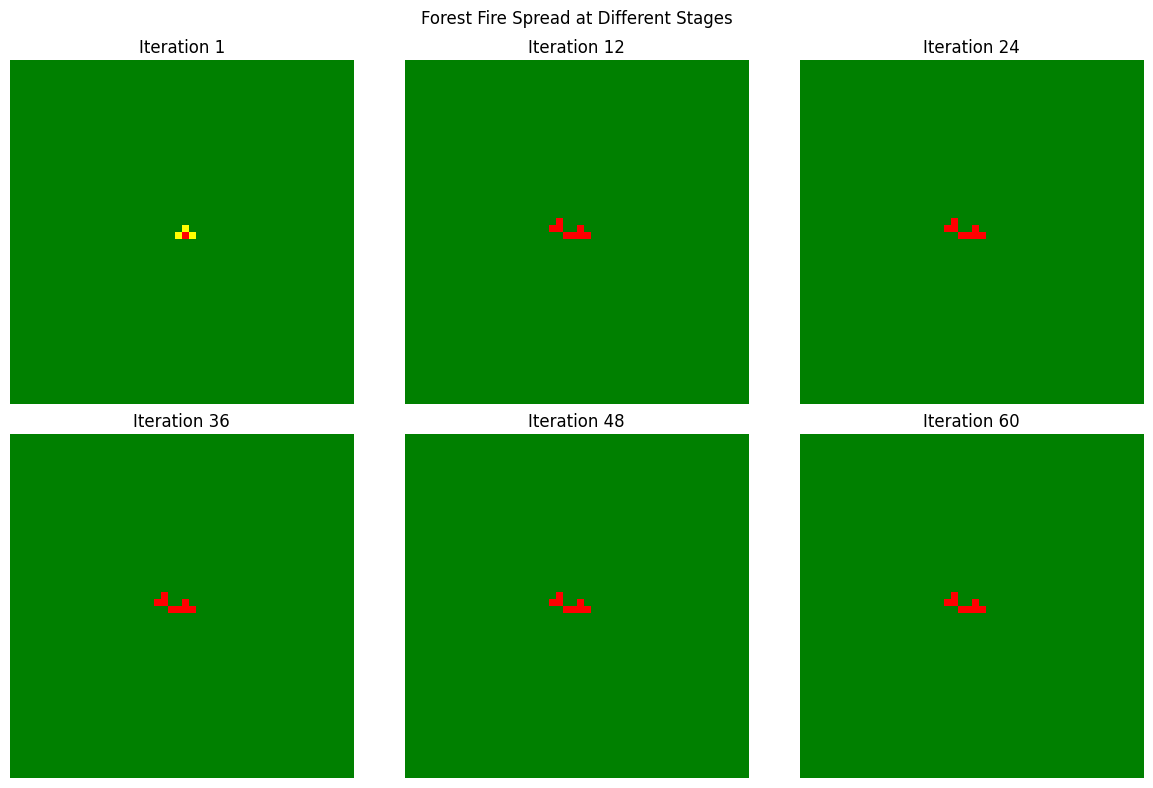


FINAL FIRE STATISTICS
Total forest cells: 2500
Burning or burnt cells: 8
Unburnt cells: 2492
Completely extinguished cells: 0


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# -----------------------------------------
# 1. INITIALIZE FOREST GRID
# -----------------------------------------

np.random.seed(42)

SIZE = 50
CELL_SIZE = 30

# Cell states:
# 0 = Unburnt
# 1 = Early burning
# 2 = Fully burning
# 3 = Extinguishing
# 4 = Completely extinguished

forest = np.zeros((SIZE, SIZE), dtype=int)

# Fuel distribution
# 1.0 = Pine forest
# 0.3 = Bare soil
fuel = np.random.choice(
    [1.0, 0.3],
    size=(SIZE, SIZE),
    p=[0.8, 0.2]
)

# Terrain slope (degrees)
slope = np.random.uniform(0, 30, (SIZE, SIZE))

# Wind conditions
temperature = 25
humidity = 40
wind_speed = 5
wind_direction = 0

# Initial fire location
forest[SIZE // 2, SIZE // 2] = 2

# Initial spread speeds
speed = np.zeros((SIZE, SIZE))

# Initial time step = 1 hour
dt0 = 60.0

# Time correction coefficient
Kr = 1 / 25

# -----------------------------------------
# 2. CALCULATE FIRE SPREAD SPEED
# -----------------------------------------

def calculate_speed():

    R = np.zeros((SIZE, SIZE))

    # Wind level
    W = int(wind_speed / 0.836) ** (2 / 3)

    # Initial fire spread speed
    R0 = (
        0.03 * temperature
        + 0.05 * W
        + 0.01 * (100 - humidity)
        - 0.3
    )

    for i in range(SIZE):
        for j in range(SIZE):

            # Wind coefficient
            phi = np.radians(wind_direction)

            Kphi = np.exp(
                0.1783 * wind_speed * np.cos(phi)
            )

            # Terrain coefficient
            theta = np.radians(slope[i, j])

            Ktheta = np.exp(
                3.553 * np.tan(1.2 * theta)
            )

            # Fuel coefficient
            Ks = fuel[i, j]

            # Final fire spread speed
            R[i, j] = (
                R0 * Kphi * Ktheta * Ks * Kr
            )

    return R


# -----------------------------------------
# 3. ADAPTIVE TIME STEP
# -----------------------------------------

def calculate_time_step(old_speed, new_speed):

    change = new_speed - old_speed

    # Speed change rate index
    a = np.zeros((SIZE, SIZE))

    active = forest == 2

    a[active] = change[active]

    # Limit extreme time-step changes
    a = np.clip(a, -2, 1)

    # Adaptive time-step equation
    dt = dt0 / np.exp(a)

    return dt, a


# -----------------------------------------
# 4. NEIGHBOUR CHECKING
# -----------------------------------------

def get_neighbors(i, j):

    neighbors = []

    for di in [-1, 0, 1]:
        for dj in [-1, 0, 1]:

            if di == 0 and dj == 0:
                continue

            ni = i + di
            nj = j + dj

            if 0 <= ni < SIZE and 0 <= nj < SIZE:
                neighbors.append((ni, nj))

    return neighbors


# -----------------------------------------
# 5. CELLULAR AUTOMATA SIMULATION
# -----------------------------------------

def simulate_fire():

    global forest, speed

    old_speed = calculate_speed()

    total_time = 0
    snapshots = []

    for step in range(60):

        new_speed = calculate_speed()

        dt, rate = calculate_time_step(
            old_speed, new_speed
        )

        next_forest = forest.copy()

        # Find burning cells
        burning = np.argwhere(forest == 2)

        for i, j in burning:

            neighbors = get_neighbors(i, j)

            for ni, nj in neighbors:

                # Ignite unburnt cells
                if forest[ni, nj] == 0:

                    # Diagonal cells are farther away
                    distance = CELL_SIZE * (
                        np.sqrt(2)
                        if abs(ni - i) == 1
                        and abs(nj - j) == 1
                        else 1
                    )

                    # Fire travel distance
                    spread_distance = (
                        new_speed[ni, nj] * dt[i, j]
                    )

                    # Check whether fire reaches the cell
                    if spread_distance >= distance:

                        next_forest[ni, nj] = 1

            # Burning cell starts extinguishing
            if all(
                forest[ni, nj] >= 2
                for ni, nj in neighbors
            ):
                next_forest[i, j] = 3

        # State transitions
        next_forest[forest == 1] = 2
        next_forest[forest == 3] = 4

        forest = next_forest

        total_time += np.mean(dt)

        old_speed = new_speed.copy()

        snapshots.append(forest.copy())

        if (step + 1) % 10 == 0:

            burned = np.sum(forest > 0)

            print(
                "Iteration:", step + 1,
                "| Burned cells:", burned,
                "| Adaptive time step:",
                round(np.mean(dt), 2), "minutes"
            )

        # Stop if no active burning cells remain
        if not np.any(forest == 2):
            break

    return snapshots


# -----------------------------------------
# 6. RUN SIMULATION
# -----------------------------------------

print("Starting Forest Fire Simulation...\n")

snapshots = simulate_fire()

print("\nSimulation Completed!")

# -----------------------------------------
# 7. DISPLAY FINAL RESULTS
# -----------------------------------------

colors = [
    "green",       # 0: Unburnt
    "yellow",      # 1: Early burning
    "red",         # 2: Fully burning
    "orange",      # 3: Extinguishing
    "black"        # 4: Extinguished
]

cmap = ListedColormap(colors)

plt.figure(figsize=(8, 6))

plt.imshow(forest, cmap=cmap, vmin=0, vmax=4)

plt.title("Adaptive Forest Fire Spread Simulation")

plt.colorbar(
    ticks=[0, 1, 2, 3, 4],
    label="Forest Cell State"
)

plt.show()

# -----------------------------------------
# 8. SHOW FIRE SPREAD PROGRESS
# -----------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

selected = np.linspace(
    0, len(snapshots) - 1,
    min(6, len(snapshots)),
    dtype=int
)

for ax, index in zip(axes.flat, selected):

    ax.imshow(
        snapshots[index],
        cmap=cmap,
        vmin=0,
        vmax=4
    )

    ax.set_title("Iteration " + str(index + 1))

    ax.axis("off")

for ax in axes.flat[len(selected):]:
    ax.axis("off")

plt.suptitle("Forest Fire Spread at Different Stages")
plt.tight_layout()
plt.show()

# -----------------------------------------
# 9. DISPLAY FIRE STATISTICS
# -----------------------------------------

print("\nFINAL FIRE STATISTICS")

print("Total forest cells:", SIZE * SIZE)

print("Burning or burnt cells:", np.sum(forest > 0))

print("Unburnt cells:", np.sum(forest == 0))

print("Completely extinguished cells:", np.sum(forest == 4))